<a href="https://colab.research.google.com/github/QuirozAlaniz/Desbalances/blob/main/Desbalances.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Francisco Daniel Quiroz Alaniz
\
Matrícula: 269723

Instrucciones

La presente tarea tiene como objetivo aplicar técnicas de aprendizaje automático para el tratamiento de clases no balanceadas utilizando un problema de clasificación real.

Para el desarrollo de la actividad deberán utilizar el conjunto de datos:

compustat.csv

Consideraciones importantes:

El conjunto de datos contiene 21 atributos.

El primer atributo corresponde a un índice, por lo que deberá ser ignorado durante el análisis y entrenamiento.

El último atributo corresponde a la etiqueta de clase.

Los atributos restantes deberán utilizarse como variables predictoras.

La solución deberá desarrollarse en un cuaderno de Google Colab o Jupyter Notebook almacenado en GitHub. La entrega consistirá en compartir la liga pública del notebook para su revisión.

Análisis Exploratorio de Datos (AED) - Para esta actividad revisa el Notebook que está en Teams en la Sesión 27 y que se llama DataLeakage_ClassImbalance.ipynb

Realizar:

Un diagrama de barras mostrando la distribución de las clases.

Diagramas de densidad KDE para los atributos 5 y 13.

Un análisis breve sobre el nivel de desbalance presente en el conjunto de datos.



In [69]:
#Importamos librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from collections import Counter
from imblearn.combine import SMOTEENN
from imblearn.under_sampling import OneSidedSelection
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, GridSearchCV, cross_val_score, train_test_split
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.metrics import (accuracy_score, classification_report, ConfusionMatrixDisplay, confusion_matrix, f1_score, precision_score, recall_score)

In [70]:
#Importar los datos
url = "/content/compustat.csv"
df = pd.read_csv(url)

In [71]:
df["label"].value_counts()

,count
label,
0,13137
1,520


Podemos observar que el 3.8% son etiquetas 1 y el 96.2% son etiquetas 0, o sea están muy desbalanceadas

Text(0.5, 1.0, 'Distribución de las etiquetas de clase')

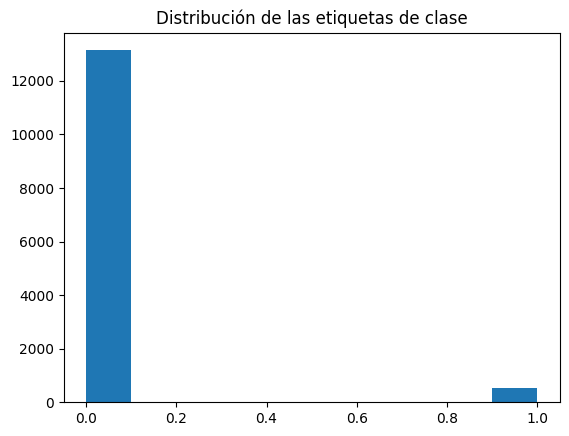

In [72]:
plt.figure()
plt.hist(df["label"])
plt.title("Distribución de las etiquetas de clase")

<Axes: xlabel='at5', ylabel='Density'>

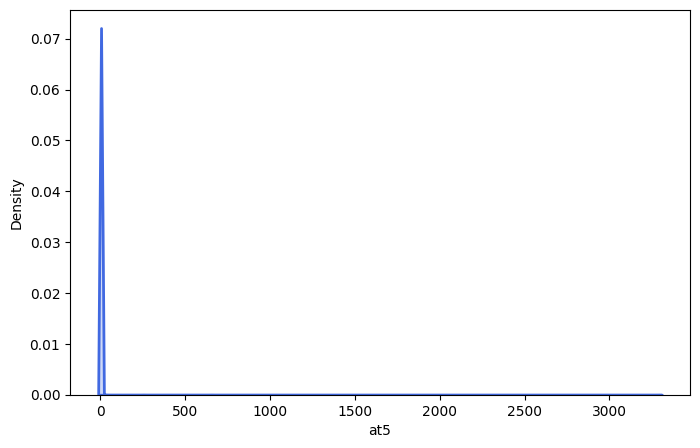

In [73]:
#Diagrama de densidad KDE
plt.figure(figsize=(8, 5))
sns.kdeplot(x=df["at5"], fill=True, color="royalblue", linewidth=2, thresh=0)


<Axes: xlabel='at13', ylabel='Density'>

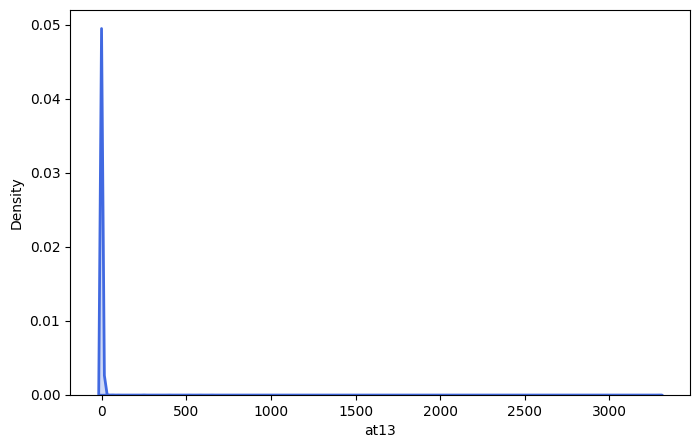

In [74]:
plt.figure(figsize=(8, 5))
sns.kdeplot(x=df["at13"], fill=True, color="royalblue", linewidth=2, thresh=0)


Podemos observar por el histograma y por los gráficos de densidad que:
\
Hay un profundo desbalance de datos tanto en la columna de etiquetas como en las variables at5 y at13

2. Modelo Base

Entrenar un modelo baseline utilizando:

Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale'))
])
\
Este modelo deberá entrenarse sin aplicar métodos de tratamiento de desbalance y servirá como referencia para comparar los resultados posteriores.

In [75]:
#Hacemos la división de los datos
#División del dataset en entrenamiento y prueba.
X = df.drop(columns = ["idx", "label"])
y = df["label"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [76]:
modelo_base = Pipeline([('scaler', StandardScaler()), ('svm', SVC(kernel='rbf', C=1.0, gamma='scale'))])

3. Tratamiento de Clases No Balanceadas

Aplicar y comparar los siguientes métodos:

SMOTEENN

One-Sided Selection

Para cada método:

Mostrar la nueva distribución de clases después del balanceo.

Entrenar nuevamente el modelo SVM utilizando los datos balanceados.

In [77]:
 #1. SMOTEENN

sme = SMOTEENN(random_state=42)
X_train_sme, y_train_sme = sme.fit_resample(X_train, y_train) #Hacemos la nueva distribución usando sme.fit_resample

# 2. Mostramos la nueva distribución de clases
print("Distribución original de clases:", Counter(y_train))
print("Nueva distribución con SMOTEENN :", Counter(y_train_sme))

# 3. Entrenamos el modelo SVM con los datos balanceados
pipeline_sme = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale'))
])

pipeline_sme.fit(X_train_sme, y_train_sme)

Distribución original de clases: Counter({0: 9180, 1: 379})
Nueva distribución con SMOTEENN : Counter({1: 9111, 0: 8085})


Pipeline(steps=[('scaler', StandardScaler()), ('svm', SVC())])

Podemos ver que la distribución original de clases era 9180 versus 379, ahora es 9111 versus 8085, es decir mucho mpas balanceada

In [78]:
#2. One-Sided Selection

# 1. Configuramos y aplicamos One-Sided Selection
oss = OneSidedSelection(random_state=42)
X_train_oss, y_train_oss = oss.fit_resample(X_train, y_train)

# 2. Mostramos la nueva distribución de clases
print("Nueva distribución con OSS:", Counter(y_train_oss))

# 3. Configuramos y entrenamos el pipeline para OSS
pipeline_oss = Pipeline([('scaler', StandardScaler()), ('svm', SVC(kernel='rbf', C=1.0, gamma='scale'))])

pipeline_oss.fit(X_train_oss, y_train_oss)

Nueva distribución con OSS: Counter({0: 9114, 1: 379})


Pipeline(steps=[('scaler', StandardScaler()), ('svm', SVC())])

Este nuevo balanceo no es tan bueno como el realizado con SMOTEENN, pues lo reconfigura a 9114 versus 379.

4. Entrenamiento y Evaluación del Modelo

Utilizar validación cruzada estratificada de 5 particiones.

Implementar el flujo de trabajo utilizando Pipeline para evitar data leakage.

Incorporar escalado de datos dentro del Pipeline.

Utilizar SVM con kernel RBF.

In [79]:
#Configuramos el validador cruzado
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [80]:
pipeline = ImbPipeline([('balanceo', SMOTEENN(random_state=42)),('scaler', StandardScaler()), ('svm', SVC(kernel='rbf', C=1.0, gamma='scale'))]) #Flujo de trabajo
#El StandardScaler hace el escalado de los datos dentro del Pipeline
#El modelo es una Máquina de Soporte Vectorial con kernel RBF


In [81]:
# Usamos f1_macro como métrica porque los datos originales están desbalanceados
resultados_sme = cross_val_score(pipeline, X, y, cv=cv, scoring='f1_macro')

print("--- VALIDACIÓN CRUZADA CON SMOTEENN ---")
print(f"F1-Scores por partición: {resultados_sme}")
print(f"F1-Score promedio: {resultados_sme.mean():.4f}")

--- VALIDACIÓN CRUZADA CON SMOTEENN ---
F1-Scores por partición: [0.57505656 0.55655582 0.5640166  0.5664278  0.58332119]
F1-Score promedio: 0.5691


Evaluación de Resultados

Reportar y analizar al menos las siguientes métricas:

Accuracy

Precision

Recall

F1-score

Matriz de confusión

In [82]:
# 1. Entrenar el Modelo Base con el conjunto de entrenamiento original
modelo_base.fit(X_train, y_train)

# 2. Generamos predicciones en el conjunto de prueba (X_test)
y_pred_base = modelo_base.predict(X_test)   #Con el modelo base original
y_pred_sme = pipeline_sme.predict(X_test)   #Con SME
y_pred_oss = pipeline_oss.predict(X_test)   #Con OSS

# 3. Creamos una tabla comparativa de métricas
modelos = {"Métricas del modelo base": y_pred_base, "Métricas del modelo usando SME": y_pred_sme, "Métricas usando OSS": y_pred_oss}

metricas = []

for nombre, y_pred in modelos.items():
    metricas.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score (Clase 1)": f1_score(y_test, y_pred),
        "F1-Score (Macro)": f1_score(y_test, y_pred, average='macro')
    })

df_metricas = pd.DataFrame(metricas)
print("===  Métricas en el conjunto de pureba ===")
display(df_metricas)



===  Métricas en el conjunto de pureba ===


,Modelo,Accuracy,Precision,Recall,F1-Score (Clase 1),F1-Score (Macro)
0,Métricas del modelo base,0.965837,1.000000,0.007092,0.014085,0.498351
1,Métricas del modelo usando SME,0.807955,0.133787,0.836879,0.230694,0.560489
2,Métricas usando OSS,0.965837,1.000000,0.007092,0.014085,0.498351


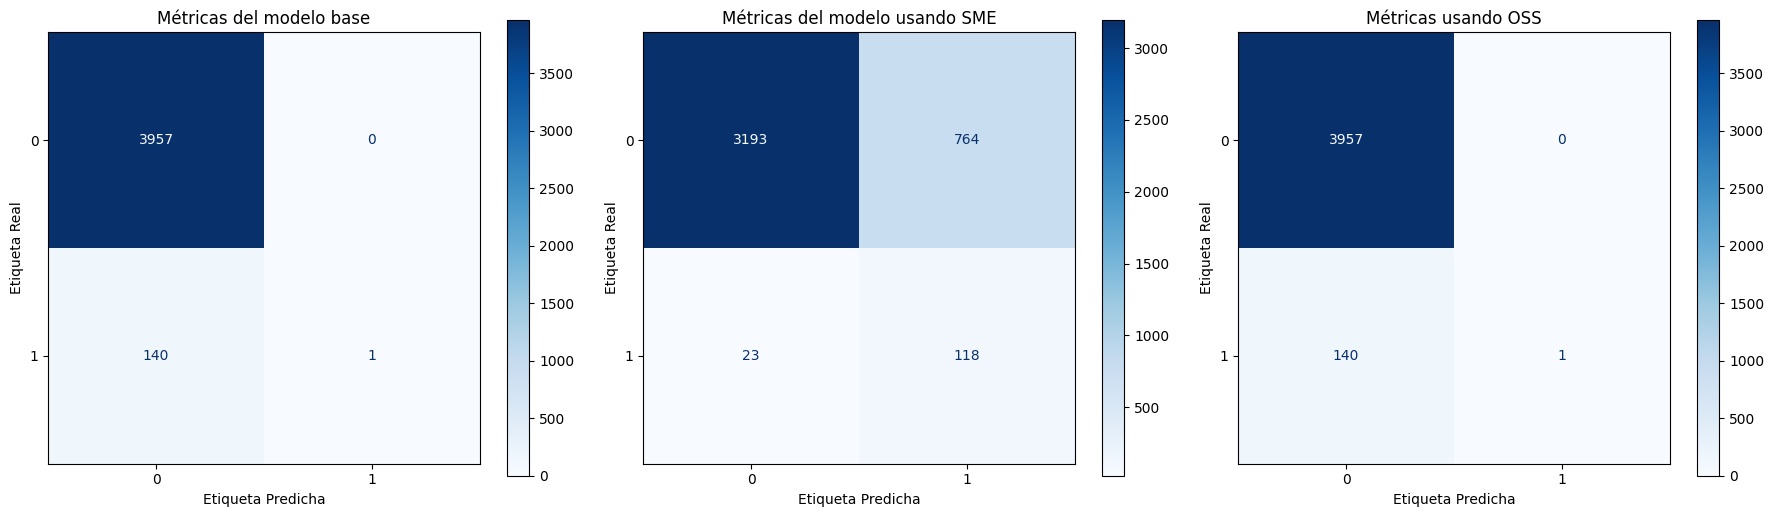

In [83]:
# 4. Graficamos las matrices de confusión
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (nombre, y_pred) in zip(axes, modelos.items()):
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
    disp.plot(ax=ax, cmap="Blues", values_format="d")
    ax.set_title(nombre)
    ax.set_ylabel("Etiqueta Real")
    ax.set_xlabel("Etiqueta Predicha")

plt.tight_layout()
plt.show()



In [84]:
# 5. Imprimimos el reporte de clasificación para cada modelo
for nombre, y_pred in modelos.items():
    print(f"\nReporte: {nombre}")
    print(classification_report(y_test, y_pred, digits=4)) #classification_report nos da


Reporte: Métricas del modelo base
              precision    recall  f1-score   support

           0     0.9658    1.0000    0.9826      3957
           1     1.0000    0.0071    0.0141       141

    accuracy                         0.9658      4098
   macro avg     0.9829    0.5035    0.4984      4098
weighted avg     0.9670    0.9658    0.9493      4098


Reporte: Métricas del modelo usando SME
              precision    recall  f1-score   support

           0     0.9928    0.8069    0.8903      3957
           1     0.1338    0.8369    0.2307       141

    accuracy                         0.8080      4098
   macro avg     0.5633    0.8219    0.5605      4098
weighted avg     0.9633    0.8080    0.8676      4098


Reporte: Métricas usando OSS
              precision    recall  f1-score   support

           0     0.9658    1.0000    0.9826      3957
           1     1.0000    0.0071    0.0141       141

    accuracy                         0.9658      4098
   macro avg     0.982

Recordemos que classification_report nos da los resultados de Precision, Recall, F1_Score y Support.
\
Podemos observar que en el modelo base, nos arroja una precisión de .9658 para la etiqueta 0, y para la etiqueta 1 un 1 o sea ajuste perfecto.
\
Pero en la columna Recall (positivos verdaderos) nos arroja que para la etiqueta 0 tenemos 1 (ajuste perfecto) pero para las etiquetas 1, apenas un .0071, es decir, es un muy mal ajuste. Esto se debe al desbalance tan fuerte de los datos.

Por otro lado, al usar pipelines con diferentes técnicas de balance de clases la historia cambia.
\
SME: el mejor de todos, si vemos la columna de Recall, podemos ver la precisión para la etiqueta 0 un .8069 y para la etiqueta 1 un .8369
\
Por otro lado OSS en la columna de recall su resultado es prácticamente el mismo que las claeses desbalanceadas, de hecho podemos ver desde el principio que no balancea muy bien las clases esta técnica con respecto al balance original.

Además:

Comparar los resultados del modelo baseline contra los modelos balanceados.

Generar una gráfica comparativa de métricas.

Analizar si Accuracy es suficiente para evaluar el problema.

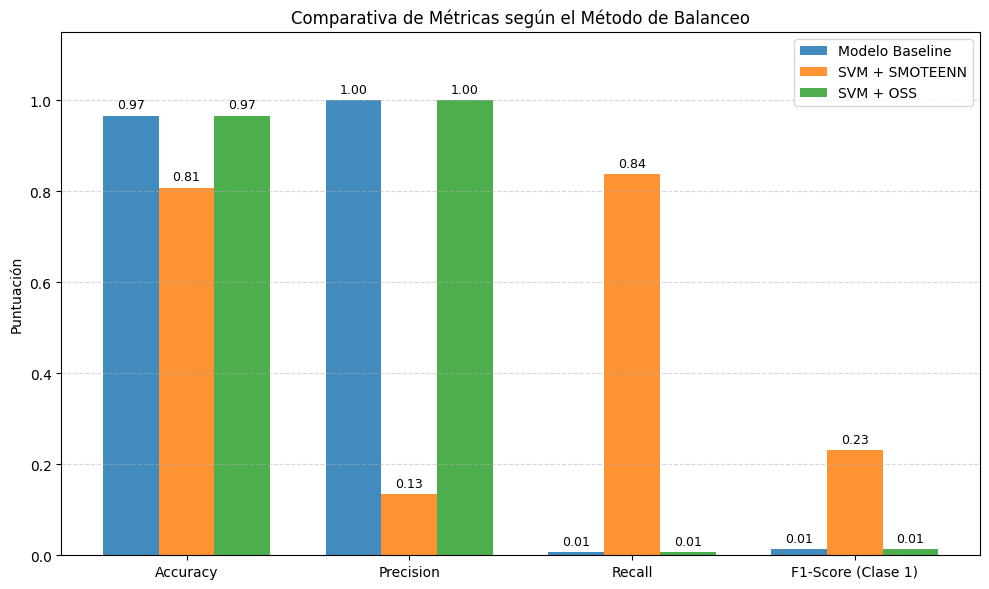

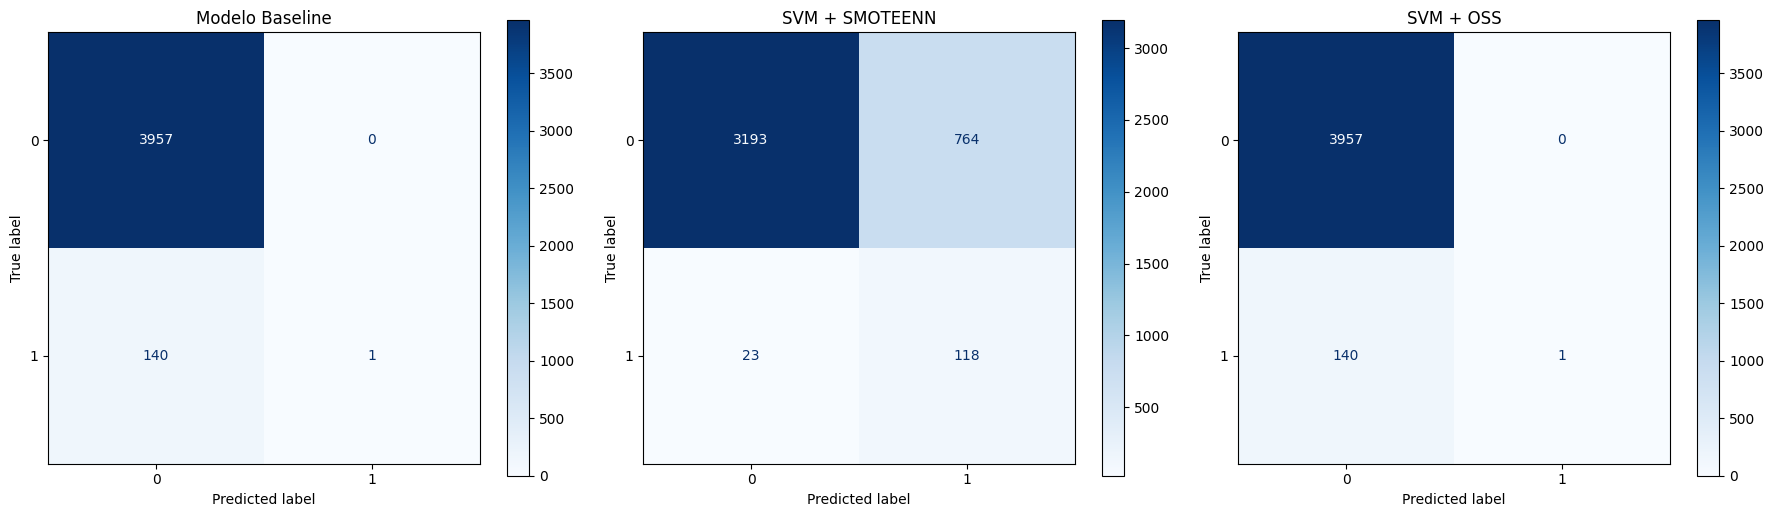

In [85]:
# 1. Entrenamos el Modelo Base con el conjunto de entrenamiento original sin balancear
modelo_base.fit(X_train, y_train)

# 2. Obtenemos predicciones en el conjunto de prueba (X_test)
y_pred_base = modelo_base.predict(X_test)   #Predicciones usando el modelo base
y_pred_sme = pipeline_sme.predict(X_test)   #Predicciones usando el modelo SME
y_pred_oss = pipeline_oss.predict(X_test)   #Predicciones usando el modelo OSS

modelos_dict = {"Modelo Baseline": y_pred_base, "SVM + SMOTEENN": y_pred_sme, "SVM + OSS": y_pred_oss,}

# 3. Comparando métricas
resultados = []

for nombre, y_pred in modelos_dict.items():
    resultados.append(
        {
            "Modelo": nombre,
            "Accuracy": accuracy_score(y_test, y_pred),
            "Precision": precision_score(y_test, y_pred, zero_division=0),
            "Recall": recall_score(y_test, y_pred),
            "F1-Score (Clase 1)": f1_score(y_test, y_pred),
            "F1-Macro": f1_score(y_test, y_pred, average="macro"),
        }
    )

df_resultados = pd.DataFrame(resultados)


# 4. Gráfica Comparativa de Métricas por Modelo
fig, ax = plt.subplots(figsize=(10, 6))

metricas_plot = ["Accuracy", "Precision", "Recall", "F1-Score (Clase 1)"]
x = np.arange(len(metricas_plot))
width = 0.25

for i, row in df_resultados.iterrows():
    valores = [row[m] for m in metricas_plot]
    rects = ax.bar(
        x + i * width, valores, width, label=row["Modelo"], alpha=0.85
    )
    ax.bar_label(rects, padding=3, fmt="%.2f", fontsize=9)

ax.set_ylabel("Puntuación")
ax.set_title("Comparativa de Métricas según el Método de Balanceo")
ax.set_xticks(x + width)
ax.set_xticklabels(metricas_plot)
ax.set_ylim(0, 1.15)
ax.legend(loc="upper right")
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# 5. Visualización de Matrices de Confusión
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (nombre, y_pred) in zip(axes, modelos_dict.items()):
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
    disp.plot(ax=ax, cmap="Blues", values_format="d")
    ax.set_title(nombre)

plt.tight_layout()
plt.show()

Al observar la métrica de Accuracy podemos darnos cuenta que es muy engañoso porque puede dar resultados muy buenos en algunos casos, por ejemplo en el modelo base tuvo un accuracy de .9658 lo cual podría parecer muy bueno al principio, pero al ver la clase 1 en la métrica Recall (positivos reales) vemos que la exactitud es muy pobre, apenas el .0071 , justamente porque la distribución de las etiquetas de las clases está fuertemente desbalanceado.
\
Además recordemos que Accuracy usa una fórmula muy simple: casos_acertados/casos_totales, por lo que si las clases están muy debalanceadas, basta con que aprenda muy bien lo de la clase mayoritaria para que nos arroje una precisión altísima, pero no significa que esté aprendiendo bien lo de la clase minoritaria.

Discusión y Conclusiones

Discutir:

El impacto del desbalance sobre el desempeño del modelo.

Las diferencias observadas entre SMOTEENN y One-Sided Selection.

Qué método produjo los mejores resultados y por qué.

El impacto del desbalance sobre el desempeño del modelo lo podemos observar en las diferentes métricas que usamos sobre los modelos de balanceo: SME y OSS, cada uno modifica el desbalance de manera diferente.
\
Pudimos ver que el modelo de SME produjo los mejores resultados porque balancea mejor los datos, por ejemplo OSS apenas modificó un poco el balanceo: 9114 versus 379, cuando el original era 13137 Versus 520. Por eso las métricas salen igual en este caso que con el modelo base.
